In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from turbofan.data import load_cmapss, add_rul, SENSOR_COLS


In [2]:
train = load_cmapss(Path("../data/raw/train_FD001.txt"))
train = add_rul(train)

In [3]:
constant_cols = [c for c in train.columns if train[c].std() < 1e-4]
useful_sensors = [s for s in SENSOR_COLS if s not in constant_cols]
print(f"Constant Cols:", constant_cols)
print(f"Length of useful sensors: {len(useful_sensors)}, Useful Sensors:", useful_sensors)

Constant Cols: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Length of useful sensors: 15, Useful Sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


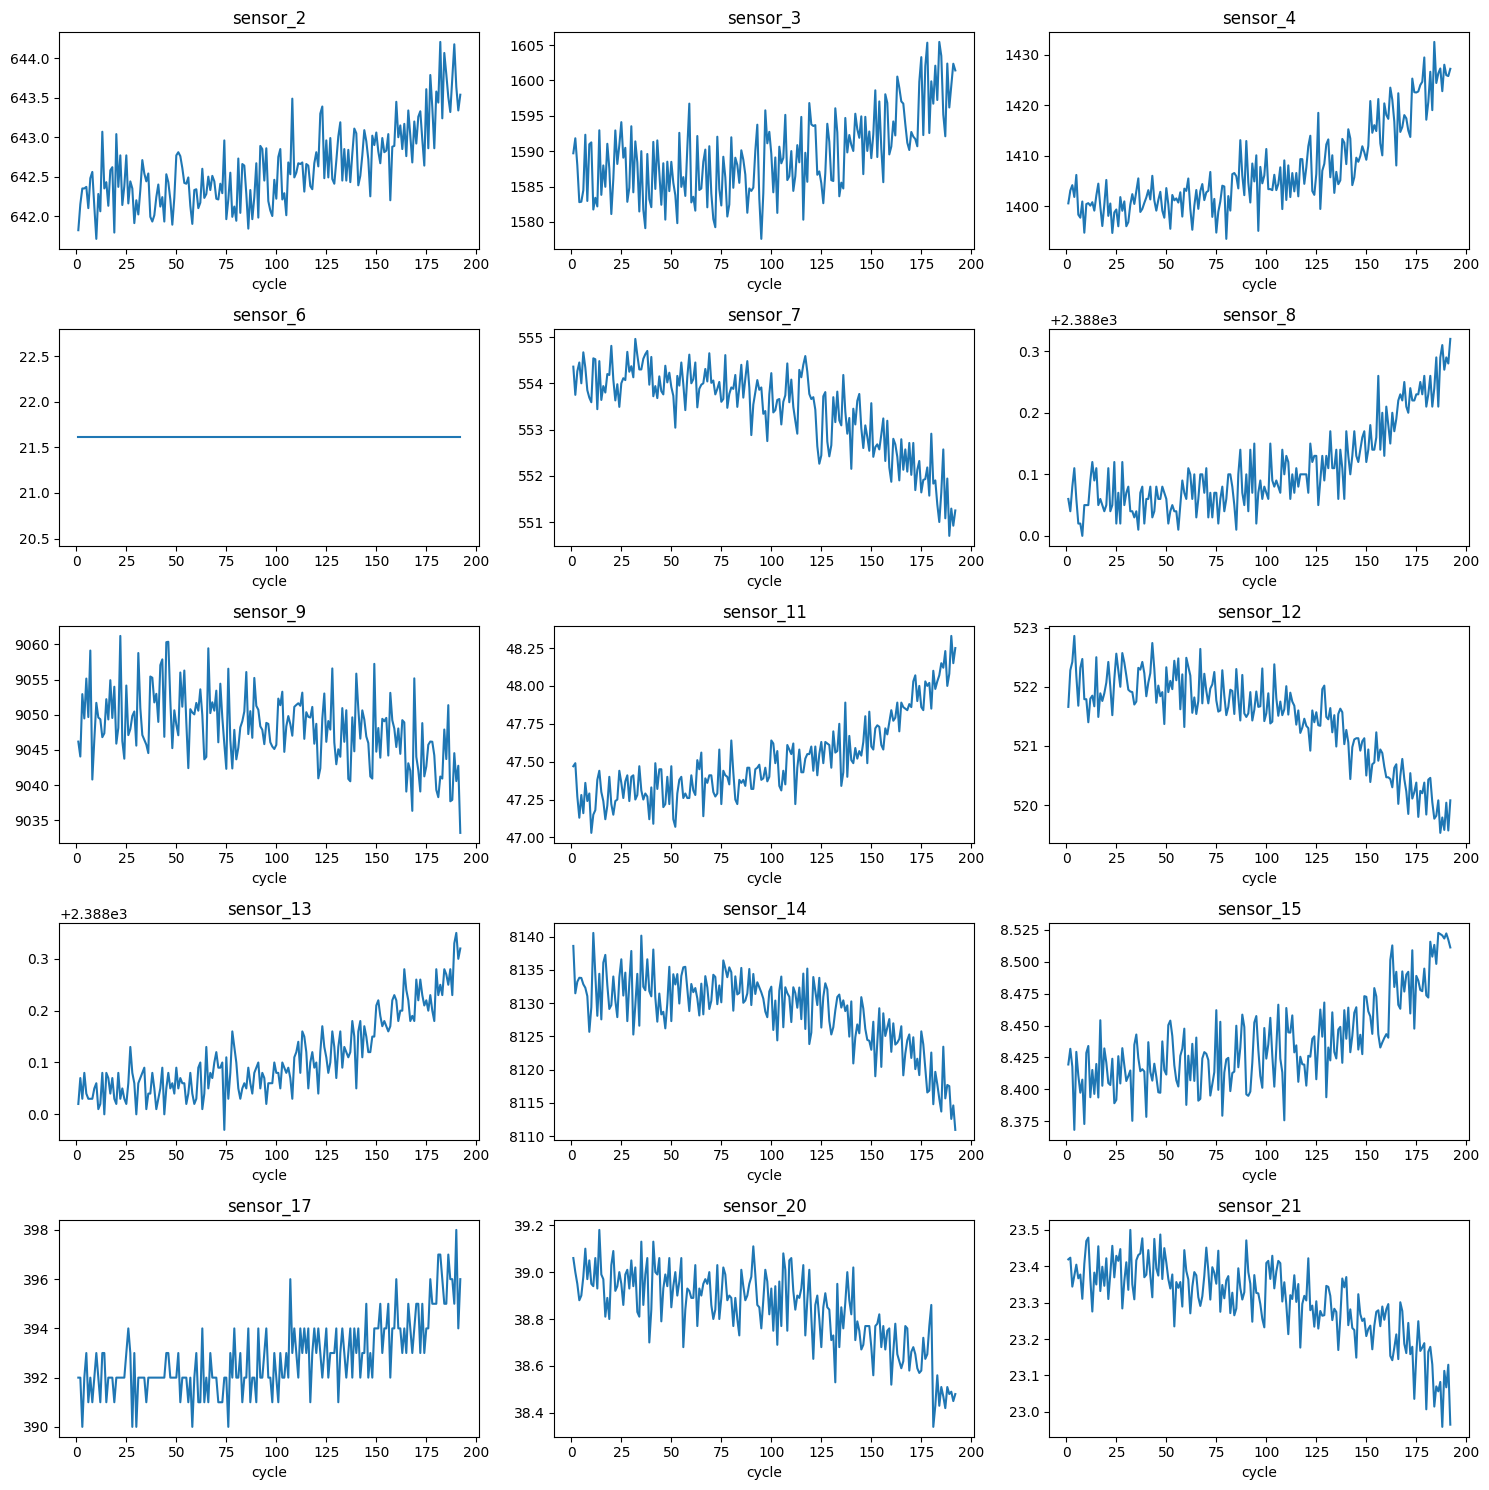

In [4]:
engine1 = train[train["unit"] == 1]

fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15, 15))
for ax, sensor in zip(axes.flatten(), useful_sensors):
    ax.plot(engine1["cycle"], engine1[sensor])
    ax.set_title(sensor)
    ax.set_xlabel("cycle")

plt.tight_layout()
plt.show()

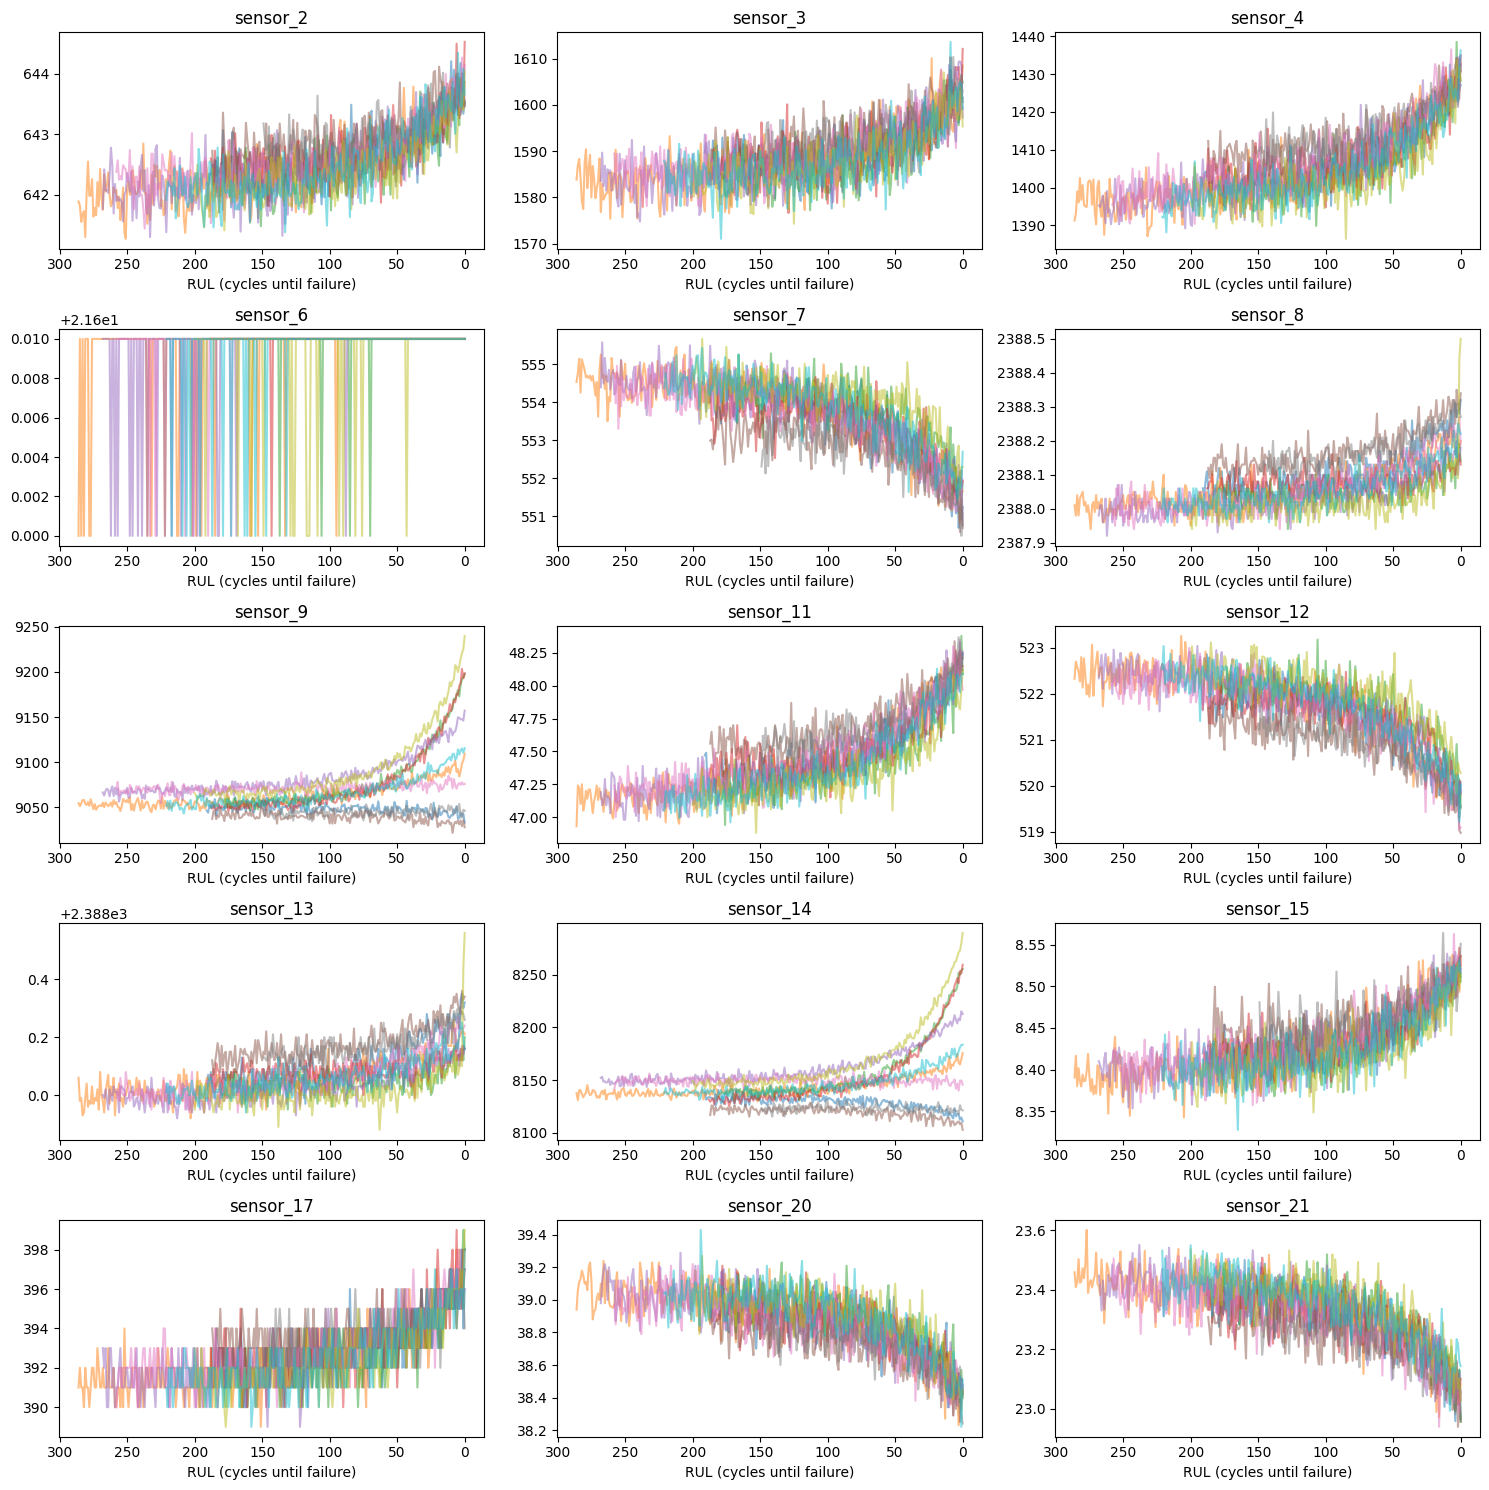

In [5]:
sample_units = train["unit"].unique()[:10]
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15, 15))

for ax, sensor in zip(axes.flatten(), useful_sensors):
    for unit in sample_units:
        engine = train[train["unit"] == unit]
        ax.plot(engine["rul"], engine[sensor], alpha=0.5)
    ax.set_title(sensor)
    ax.set_xlabel("RUL (cycles until failure)")
    ax.invert_xaxis()

plt.tight_layout()
plt.show()

In [6]:
train["unit"].unique()[:10]

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [7]:
corr_with_rul = train[useful_sensors + ["rul"]].corr()["rul"].drop("rul")
print(corr_with_rul.sort_values())

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
Name: rul, dtype: float64


In [8]:
# Random split, chance of data leakage
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

In [9]:
X = train[useful_sensors]
y = train["rul"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=41)

model = RandomForestRegressor(n_estimators=100, random_state=41, n_jobs=-1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
rmse_random = root_mean_squared_error(y_test, y_pred)
print(rmse_random)

42.012107117342495


In [10]:
# separating whole engine as a test data, prevents data leakage problem
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=41)
train_idx, test_idx = next(gss.split(X, y, groups=train["unit"]))

X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

model = RandomForestRegressor(n_estimators=100, random_state=41, n_jobs=-1)
model.fit(X_tr, y_tr)
pred = model.predict(X_te)
rmse_engine = root_mean_squared_error(y_te, pred)
print(f"Engine split RMSE:     {rmse_engine:.1f} cycles")
print(f"Random-row split RMSE: {rmse_random:.1f} cycles")

Engine split RMSE:     48.2 cycles
Random-row split RMSE: 42.0 cycles


In [11]:
train_engines = set(train["unit"].iloc[train_idx])
test_engines = set(train["unit"].iloc[test_idx])
print("Overlap:", train_engines & test_engines)

Overlap: set()


In [12]:
from turbofan.data import split_by_engine

tr, val = split_by_engine(train)
print(tr["unit"].nunique(), "train engines,", val["unit"].nunique(), "validation engines")
print("Overlap:", set(tr["unit"]) & set(val["unit"]))

80 train engines, 20 validation engines
Overlap: set()
